# Polynomial Regression

In [1]:
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.model_selection  import train_test_split
from sklearn.linear_model import LinearRegression , SGDRegressor
from sklearn.preprocessing import PolynomialFeatures , StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

In [2]:
X = 6* np.random.rand(200,1) -3
Y= 0.8 * X**2  +0.9* X+2 + np.random.randn(200,1)

# y = 0.8 x^2 + 0.9x +2

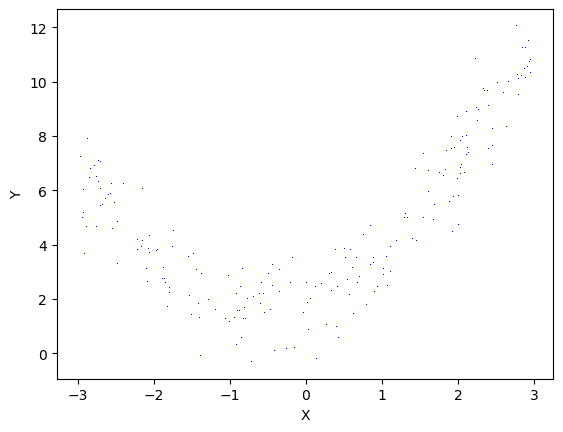

In [3]:
plt.plot(X,Y , 'b,')
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [4]:
# Train test split
X_train , X_test , Y_train , Y_test = train_test_split(X,Y ,test_size = 0.2 , random_state=2)

In [5]:
# applying linear regession 
lr = LinearRegression()

In [6]:
lr.fit(X_train , Y_train)

LinearRegression()

In [7]:
Y_pred = lr.predict(X_test)
r2_score(Y_test,Y_pred)


0.16326837860635168

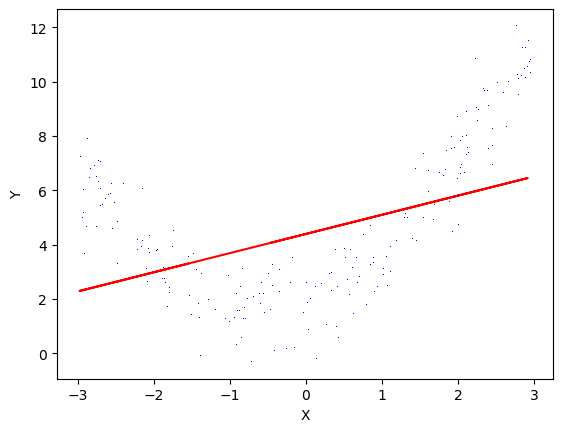

In [8]:
plt.plot(X_train , lr.predict(X_train) , color = 'red' )
plt.plot(X,Y , 'b,')
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [9]:
# applying polunomial linear regression 
# degree 2
poly = PolynomialFeatures(degree=2 , include_bias =True)

X_train_trans = poly.fit_transform(X_train)
X_test_trans = poly.transform(X_test)

In [10]:
print(X_train[0])
print(X_train_trans[0])

[-1.55103476]
[ 1.         -1.55103476  2.40570882]


In [11]:
# include _bias parameter


In [12]:
lr = LinearRegression()
lr.fit(X_train_trans , Y_train)


LinearRegression()

In [13]:
Y_pred = lr.predict(X_test_trans)

In [14]:
r2_score(Y_test ,Y_pred)

0.9042090623590904

In [15]:
print(lr.coef_)
print(lr.intercept_)

[[0.         0.83714241 0.8034125 ]]
[1.91386442]


In [16]:
X_new = np.linspace(-3,3,200).reshape(200,1)
X_new_poly = poly.transform(X_new)
Y_new = lr.predict(X_new_poly)

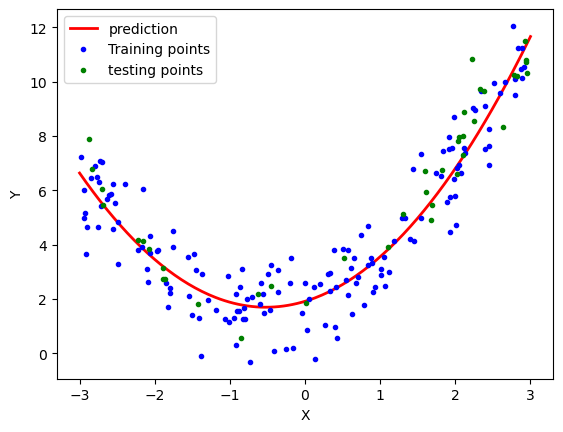

In [17]:
plt.plot(X_new , Y_new , "r-" , linewidth = 2 , label = "prediction")
plt.plot(X_train , Y_train , "b." , label = 'Training points')
plt.plot(X_test , Y_test , "g." , label = "testing points")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

In [18]:
def polynomial_regression(degree):
    X_new = np.linspace(-3,3,100).reshape(100,1)
    X_new_poly = poly.transform(X_new)

    polybig_features = PolynomialFeatures(degree = degree , include_bias =False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = Pipeline([
        ("poly_features" , polybig_features),
        ("std_scaler" , std_scaler),
        ("lin_reg" , lin_reg),
    ])
    polynomial_regression.fit(X,Y)
    Y_newbig = polynomial_regression.predict(X_new)
    plt.plot(X_new ,Y_newbig ,'r' , label = "degree" + str(degree) , linewidth = 2)


    plt.plot(X_train,Y_train ,"b." , linewidth=3)
    plt.plot(X_test,Y_test , "g." , linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.axis([-3,3,0,10])
    plt.show()


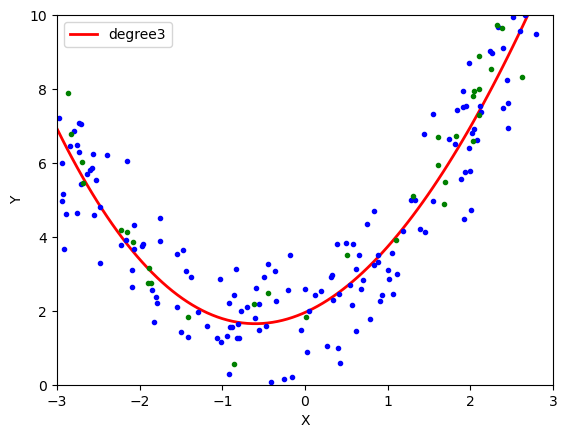

In [19]:
polynomial_regression(3)

In [48]:
# 3d ploynomial regression
X = 7 * np.random.rand(100,1)-2.8
Y = 7 * np.random.rand(100,1) - 2.8

Z = X**2 + Y**2 + 0.2*X + 0.2*Y + 0.1 *X*Y + 2 + np.random.rand(100,1)

In [49]:
import plotly.express as px
df = px.data.iris()
fig = px.scatter_3d(df , x= X.ravel() , y = Y.ravel() , z = Z.ravel() )
fig.show()

In [50]:
lr = LinearRegression()
lr.fit(np.array([X,Y]).reshape(100,2),Z)

X_input = np.linspace(X.min(),X.max(),10)
Y_input = np.linspace(Y.min(),Y.max(),10)
Xgrid , Ygrid = np.meshgrid(X_input ,Y_input)

final = np.vstack((Xgrid.ravel().reshape(1,100) , Ygrid.ravel().reshape(1,100))).T

Z_final = lr.predict(final).reshape(10,10)

In [52]:
import plotly.graph_objects as go
fig = px.scatter_3d(df , x = X.ravel() , y = Y.ravel() , z= Z.ravel())

fig.add_trace(go.Surface(x = X_input , y = Y_input , z = Z_final))

fig.show()

In [53]:
X_multi = np.array([X,Y]).reshape(100,2)
X_multi.shape

(100, 2)

In [61]:
poly = PolynomialFeatures(degree = 6)
X_multi_trans = poly.fit_transform(X_multi)

In [69]:
print("Input" , poly.n_features_in_)
print("Output" , poly.n_output_features_)
print("Power\n" , poly.powers_)

Input 2
Output 28
Power
 [[0 0]
 [1 0]
 [0 1]
 [2 0]
 [1 1]
 [0 2]
 [3 0]
 [2 1]
 [1 2]
 [0 3]
 [4 0]
 [3 1]
 [2 2]
 [1 3]
 [0 4]
 [5 0]
 [4 1]
 [3 2]
 [2 3]
 [1 4]
 [0 5]
 [6 0]
 [5 1]
 [4 2]
 [3 3]
 [2 4]
 [1 5]
 [0 6]]


In [70]:
X_multi_trans.shape

(100, 28)

In [71]:
lr = LinearRegression()
lr.fit(X_multi_trans,Z)



LinearRegression()

In [65]:
X_test_multi = poly.transform(final)


In [73]:
Z_final = lr.predict(X_multi_trans).reshape(10,10)


In [74]:
fig = px.scatter_3d(x = X.ravel() , y = Y.ravel() , z = Z.ravel())

fig.add_trace(go.Surface(x =X_input , y =Y_input ,z = Z_final))

fig.update_layout(scene = dict(zaxis = dict(range = [0,35])))

fig.show()